# Training the Force Fields

> **About this notebook, version 1.0.0 (17 November 2026).** The fourth of five notebooks of *Polymer Neural Nets*. Equation numbers such as (2.6) refer to the theory notebook 00, and the data and the network input are described in notebook 01. The full models in `models/` were trained with `scripts/train.py`; this notebook inspects them and repeats a short training live. Python 3.14 with NumPy, Matplotlib, PyTorch and PyTorch Geometric.

*Force matching on OpenMM data: the loss, one gradient step taken apart, a live training run, the learning curves of the full models, and how well they do on chains they have never seen*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="22">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

Two graph networks, the SchNet-style `InvariantGNN` (61 000 weights) and the EGNN-style `EquivariantGNN` (98 000 weights), learn the energy of a 32-bead Kremer–Grest chain from 1800 OpenMM frames. The loss compares their forces, computed as derivatives of the energy, with the exact forces, and adds a small energy term. Section 1 sets up the data and the loss. Section 2 takes one gradient step apart: it shows that the gradient of a loss built from forces needs second derivatives of the network, and checks it against finite differences. Section 3 trains a small network live, and section 4 shows the learning curves of the full models. Their force error falls to about 1% of the typical force in 20–25 epochs of about 12 s each on one CPU core. Section 5 tests the models on a 64-bead chain that was never used for training: the force error stays at about 1%, and the energy is right up to a constant. Section 6 explains that constant. Data at a single chain length cannot decide how a constant energy is shared between end beads and interior beads; with two lengths the split can be measured, and it is.

**Keywords:** force matching; loss function; second derivatives; double backpropagation; Adam; cosine schedule; gradient clipping; learning curve; validation; transferability; parity plot; energy offset; identifiability

## Index

- Section 1, data and loss: Eqs. (1)–(2), Table 1, cell c.1.
- Section 2, one gradient step taken apart: Eq. (3), Tables 2–3, cell c.2.
- Section 3, a live training run: Table 4, cell c.3.
- Section 4, the full models: Figure 1, Table 5, cell c.4.
- Section 5, chains never seen: Figures 2–3, Table 6, cell c.5.
- Section 6, the energy constant: Eqs. (4)–(5), Theorem 1, Table 7, cell c.6.
- Section 7, training your own models: Table 8.

## 0. Settings

Cell c.0 makes the notebook run in any Jupyter: it installs missing libraries, finds the repository folder or downloads it once from GitHub into `~/polymer-neural-nets` when this notebook is opened on its own, and sets the style of figures and tables.

In [1]:
# c.0
# Setup. This cell makes the notebook run in any Jupyter, three ways:
#  (1) inside the repository folder (e.g. `uv run jupyter lab`, or `pip install -r requirements.txt` then `jupyter lab`);
#  (2) in any Python environment: libraries that are missing are installed with pip into this kernel;
#  (3) as a single notebook file on its own: the code and data of the repository are downloaded once from
#      GitHub into the folder polymer-neural-nets in your home folder.
import importlib.util, subprocess, sys, io, zipfile, urllib.request, warnings
from pathlib import Path
warnings.filterwarnings("ignore")   # library notices (tqdm, TorchScript) are not part of the results
NEED = {"numpy": "numpy", "scipy": "scipy", "sympy": "sympy", "matplotlib": "matplotlib", "torch": "torch",
        "torch_geometric": "torch-geometric", "openmm": "openmm", "IPython": "ipython"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if sys.platform == "emscripten":                                 # JupyterLite / Pyodide: Python inside the web page
    raise SystemExit("\n".join([
        "This Jupyter runs Python inside the web browser (JupyterLite / Pyodide, WebAssembly).",
        "PyTorch and OpenMM are not available there, and nothing can be installed with pip, so this notebook",
        "cannot run in it. The saved results are still shown in the notebook, and in the .md and .pdf editions.",
        "",
        "To run it, use Jupyter with a real Python on your computer. It also opens in the browser. In a terminal:",
        "  1. install uv (once):   curl -LsSf https://astral.sh/uv/install.sh | sh",
        "                          (Windows PowerShell: irm https://astral.sh/uv/install.ps1 | iex)",
        "  2. get the repository:  git clone https://github.com/lossofgenerality/polymer-neural-nets",
        "                          cd polymer-neural-nets",
        "  3. install and start:   uv sync   then   uv run jupyter notebook",
        "Then open this notebook in the Jupyter tab that appears and choose Kernel → Restart Kernel and Run All Cells."]))
def install(pkgs):
    """Install pkgs into the Python of this kernel; try pip, then uv; explain clearly if neither works."""
    import shutil
    tries = [[sys.executable, "-m", "pip", "install", *pkgs]]
    if shutil.which("uv"):
        tries.append(["uv", "pip", "install", "--python", sys.executable, *pkgs])
    errors = []
    for cmd in tries:
        try:
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode == 0:
                importlib.invalidate_caches(); return
            errors.append(f"{' '.join(cmd[:4])} …: exit code {r.returncode}\n{(r.stderr or r.stdout)[-1200:]}")
        except OSError as e:
            errors.append(f"{' '.join(cmd[:4])} …: could not be started ({e})")
    managed = any("externally-managed" in e for e in errors)
    raise SystemExit("\n".join([
        "Could not install " + ", ".join(pkgs) + " into the Python of this Jupyter kernel:", "    " + sys.executable, "",
        *errors, "",
        "Fix it in a terminal, in the folder of this repository, with one of these, then restart the kernel:",
        "  (a) uv:   uv sync   and then   uv run jupyter notebook      (uses the exact versions of uv.lock)",
        "  (b) venv: python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter notebook",
        "            (Windows: .venv\\Scripts\\activate)",
        f"  (c) this kernel's Python: \"{sys.executable}\" -m pip install " + " ".join(pkgs),
        "This Python is managed by the system or Homebrew and refuses installs: use (a) or (b)." if managed else ""]))
if missing:
    print("installing", ", ".join(missing), "(first run only; torch is large) ...")
    install(missing)
def find_repo():
    for q in [Path.cwd(), *Path.cwd().parents]:                  # (1) this notebook is inside the repository
        if (q / "src" / "polymer_nn").is_dir() and (q / "data").is_dir():
            return q
    home = Path.home() / "polymer-neural-nets"                    # (3) download it once
    if not (home / "src" / "polymer_nn").is_dir():
        url = "https://github.com/lossofgenerality/polymer-neural-nets/archive/refs/heads/main.zip"
        print("downloading the repository (code, data, models) from", url)
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            top = z.namelist()[0].split("/")[0]
            for m in z.infolist():
                rel = m.filename[len(top) + 1:]
                if rel and not m.is_dir():
                    (home / rel).parent.mkdir(parents=True, exist_ok=True)
                    (home / rel).write_bytes(z.read(m))
    return home
ROOT = find_repo()
sys.path.insert(0, str(ROOT / "src"))                             # use the repository's polymer_nn
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from polymer_nn import nbtools as nb
from polymer_nn.nbtools import table, nform, sci, savefig, figFont, wFull, wHalf, red, blue, green, orange, grey
nb.setup(threads=2)                 # plot style and 2 CPU threads; figures are saved in ./figures
DATA = ROOT / "data"                # the reference data made by scripts/generate_data.py
torch.manual_seed(0); rng = np.random.default_rng(0)
print("repository folder:", ROOT.name, "| Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__)

repository folder: polymer-neural-nets | Python 3.14.6 | torch 2.15.0+cu132 | numpy 2.5.5


## 1. The data and the loss

The training file `data/kg_N32.npz` holds 2000 frames of a 32-bead chain (notebook 01). `scripts/train.py` shuffles them with a fixed seed. 10% (200 frames) are set aside for *validation*: they are never used to change the weights, only to watch how the error on unseen frames develops. The other 1800 frames are for training. A constant e₀ per bead, the mean energy per bead of the file, is subtracted from every energy target (`polymer_nn.graph.to_data`). It changes no force, and it makes the energy targets of order 1 instead of about 640 ε.

The loss for a batch of B graphs with N_g beads each (`polymer_nn.train`, Eq. (T1)) is

$$
L(\theta) = \underbrace{\frac{1}{3 N_{\text{tot}}} \sum_{i} \bigl| \hat F_i - F_i \bigr|^2}_{\text{force matching}} \; + \; w_E \, \underbrace{\frac{1}{B} \sum_{g} \Bigl( \frac{\hat E_g - E_g}{N_g} \Bigr)^2}_{\text{energy per bead}} , \qquad \hat F_i = -\frac{\partial \hat E}{\partial x_i} \tag{1}
$$

with w_E = 0.05. A frame gives 3N = 96 force components but only one energy, so the forces carry almost all of the information. The energy term only keeps the absolute level of Ê in place. The optimiser is Adam (notebook 00, Eq. (2.6)) with learning rate η₀ = 2 × 10⁻³ and batches of 16 frames. The rate follows a cosine schedule over the T epochs,

$$
\eta_t = \tfrac12 \eta_0 \bigl(1 + \cos(\pi t / T)\bigr) , \tag{2}
$$

and the gradient norm is clipped at 10, so that one unusual batch cannot throw the weights far. Cell c.1 builds the data sets exactly as `scripts/train.py` does.

In [2]:
# c.1
# the training and validation sets, as in scripts/train.py
from polymer_nn.graph import dataset_from_npz
from polymer_nn.models import load_model, build_model
from polymer_nn.train import TrainConfig, fit, evaluate, _loss
data, e0 = dataset_from_npz(DATA / "kg_N32.npz", cutoff=1.5)
idx = np.random.default_rng(0).permutation(len(data)); val = [data[i] for i in idx[:200]]; train = [data[i] for i in idx[200:]]
Fall = np.concatenate([d.force.numpy().ravel() for d in train]); Eall = np.array([float(d.energy) for d in train])
table([["quantity", "value"], ["training / validation frames", f"{len(train)} / {len(val)}"],
       ["energy offset e₀ (mean energy per bead)", f"{e0:.4f} ε"], ["force components in the training set", f"{Fall.size:,}"],
       ["RMS force (the scale of the force errors)", f"{np.sqrt(np.mean(Fall**2)):.2f} ε/σ"],
       ["largest |force component|", f"{np.abs(Fall).max():.1f} ε/σ"],
       ["energy target E − N e₀: mean, std", f"{Eall.mean():.3f}, {Eall.std():.3f} ε"]], "Table 1. The training data")

quantity,value
training / validation frames,1800 / 200
energy offset e₀ (mean energy per bead),20.1168 ε
force components in the training set,"172,800"
RMS force (the scale of the force errors),25.29 ε/σ
largest |force component|,234.6 ε/σ
"energy target E − N e₀: mean, std","-0.021, 4.313 ε"


## 2. One gradient step, taken apart

The loss of Eq. (1) contains the forces F̂ = −∂Ê/∂x, which are already derivatives of the network. Its gradient with respect to a weight θ_k therefore contains second derivatives:

$$
\frac{\partial L}{\partial \theta_k} = \frac{2}{3 N_{\text{tot}}} \sum_i \bigl( \hat F_i - F_i \bigr) \cdot \frac{\partial \hat F_i}{\partial \theta_k} + \dots , \qquad \frac{\partial \hat F_i}{\partial \theta_k} = -\frac{\partial^2 \hat E}{\partial \theta_k \, \partial x_i} \tag{3}
$$

PyTorch computes this by *double backpropagation*. The first backward pass, which gives F̂, is itself recorded as a computational graph (`create_graph=True` in `models._EnergyModel.forward`), and `loss.backward()` then runs backwards through both passes. Cell c.2 takes one batch and evaluates the loss. It lists the size of the gradient in each block of the network (Table 2), and checks the autograd gradient of single weights against finite differences of the loss, in double precision (Table 3).

In [3]:
# c.2
# one batch: the loss, its gradient per block, and a finite-difference check of Eq. (3)
from torch_geometric.loader import DataLoader
torch.manual_seed(0)
small = build_model("invariant", hidden=16, layers=2).double(); small.train()
batch = next(iter(DataLoader(train, batch_size=4))); batch.pos = batch.pos.double(); batch.force = batch.force.double(); batch.energy = batch.energy.double()
cfg = TrainConfig()
loss, lf, le = _loss(small, batch, cfg); small.zero_grad(); loss.backward()
rows = [["block", "weights", "|∂L/∂θ| (Euclidean norm)"]]
for name, mod in [("embedding", small.embed)] + [(f"layer {l + 1}", c) for l, c in enumerate(small.convs)] + [("readout", small.readout)]:
    gsq = sum(float((p.grad**2).sum()) for p in mod.parameters()); rows.append([name, sum(p.numel() for p in mod.parameters()), sci(gsq**0.5)])
table([["term of Eq. (1)", "value"], ["force term", sci(float(lf))], ["energy term", sci(float(le))], ["total L", sci(float(loss))]] , "Table 2a. The loss of one batch (4 frames, untrained network)")
table(rows, "Table 2b. Size of the gradient in each block")
checks = [["weight", "autograd ∂L/∂θ", "finite difference", "relative difference"]]
for name, p, k in [("readout last bias", small.readout[-1].bias, (0,)), ("layer 1 filter weight", small.convs[0].filter[0].weight, (3, 15)),
                   ("layer 2 matrix A", small.convs[1].lin_in.weight, (2, 7)), ("embedding of end beads", small.embed.weight, (0, 4))]:
    g = float(p.grad[k]); h = 1e-6
    with torch.no_grad(): p[k] += h
    lp = float(_loss(small, batch, cfg)[0])
    with torch.no_grad(): p[k] -= 2 * h
    lm = float(_loss(small, batch, cfg)[0])
    with torch.no_grad(): p[k] += h
    fd = (lp - lm) / (2 * h); checks.append([name + " " + str(k), f"{g:.8e}", f"{fd:.8e}", sci(abs(g - fd) / max(abs(fd), 1e-12))])
table(checks, "Table 3. Double backpropagation, Eq. (3), against finite differences (float64)")

term of Eq. (1),value
force term,6.7 × 10²
energy term,6.5 × 10⁻²
total L,6.7 × 10²


block,weights,|∂L/∂θ| (Euclidean norm)
embedding,32,2.7 × 10⁻¹
layer 1,1 632,2.4 × 10⁰
layer 2,1 632,5.1 × 10⁰
readout,289,2.7 × 10⁰


weight,autograd ∂L/∂θ,finite difference,relative difference
"readout last bias (0,)",-2.52705188e-02,-2.52704808e-02,1.5 × 10⁻⁶
"layer 1 filter weight (3, 15)",-2.18598685e-02,-2.18599325e-02,2.9 × 10⁻⁶
"layer 2 matrix A (2, 7)",2.51792313e-01,2.51792358e-01,1.8 × 10⁻⁷
"embedding of end beads (0, 4)",-6.13684286e-04,-6.13738393e-04,8.8 × 10⁻⁵


Every block receives a gradient of similar size, so all of them learn from the first step. The relative differences in Table 3 are at the level of the finite-difference error (step h = 10⁻⁶), so the gradient that Adam follows is exactly the gradient of Eq. (1).

## 3. A live training run

Cell c.3 trains a smaller network (32 channels, 2 layers) on the first 300 training frames for 4 epochs, and checks it on the validation frames. It takes a few seconds. It is the same `polymer_nn.train.fit` that made the full models, with fewer frames, fewer epochs and a smaller network.

In [4]:
# c.3
# a short live training run with the library function used for the full models
torch.manual_seed(0)
demo = build_model("invariant", hidden=32, layers=2)
t0 = time.time()
h = fit(demo, train[:300], val[:100], TrainConfig(epochs=4, batch_size=16, lr=3e-3), verbose=False)
table([["epoch", "train force RMSE (ε/σ)", "validation force RMSE (ε/σ)", "validation energy RMSE per bead (ε)"]] +
      [[e, f"{a:.3f}", f"{b:.3f}", f"{c:.4f}"] for e, a, b, c in zip(h["epoch"], h["train_force_rmse"], h["val_force_rmse"], h["val_energy_rmse_per_bead"])],
      f"Table 4. Live training: 300 frames, 4 epochs, {time.time() - t0:.0f} s (RMS force {h['force_scale']:.1f} ε/σ)")

epoch,train force RMSE (ε/σ),validation force RMSE (ε/σ),validation energy RMSE per bead (ε)
1,20.397,10.962,4.2320
2,8.118,6.227,6.3914
3,5.138,5.090,5.2856
4,4.496,4.720,4.7110


Within a few epochs the force error drops from the size of the forces themselves (an untrained network predicts nearly zero force) to a few ε/σ. The full models below train on all 1800 frames for 20–25 epochs with larger networks.

## 4. The full models

`models/invariant.pt` and `models/egnn.pt` were trained with

```
uv run python scripts/train.py --data data/kg_N32.npz --test data/kg_N64.npz --model invariant --epochs 25 --out models/invariant.pt
uv run python scripts/train.py --data data/kg_N32.npz --test data/kg_N64.npz --model egnn --epochs 20 --out models/egnn.pt
```

on one CPU core, in about 5 minutes each. Their training histories are stored next to them as JSON. Cell c.4 draws the learning curves (Figure 1) and summarises the final errors (Table 5).

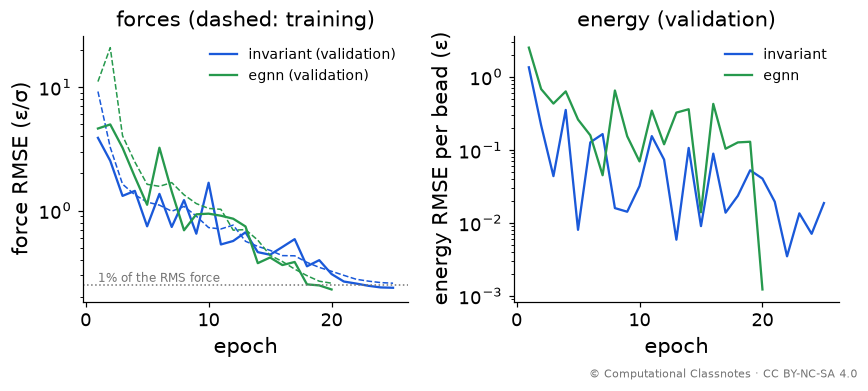

model,weights,epochs,final validation force RMSE,as % of RMS force,validation energy RMSE / bead
invariant,"60,801",25,0.238 ε/σ,0.94 %,0.0188 ε
egnn,"98,052",20,0.231 ε/σ,0.91 %,0.0012 ε


In [5]:
# c.4
# learning curves of the full models
H = {n: json.loads((ROOT / f"models/{n}.json").read_text()) for n in ("invariant", "egnn")}
scale = H["invariant"]["force_scale"]
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.3, wHalf * 1.2))
for n, c in (("invariant", blue), ("egnn", green)):
    ax[0].plot(H[n]["epoch"], H[n]["train_force_rmse"], "--", color=c, lw=1); ax[0].plot(H[n]["epoch"], H[n]["val_force_rmse"], color=c, label=f"{n} (validation)")
    ax[1].plot(H[n]["epoch"], H[n]["val_energy_rmse_per_bead"], color=c, label=n)
ax[0].axhline(0.01 * scale, color=grey, ls=":", lw=1); ax[0].text(1, 0.0105 * scale, "1% of the RMS force", fontsize=8, color=grey)
ax[0].set(yscale="log", xlabel="epoch", ylabel="force RMSE (ε/σ)", title="forces (dashed: training)"); ax[0].legend(fontsize=9)
ax[1].set(yscale="log", xlabel="epoch", ylabel="energy RMSE per bead (ε)", title="energy (validation)"); ax[1].legend(fontsize=9)
fig.tight_layout(); savefig(fig, "fig1_learning_curves"); plt.show()
table([["model", "weights", "epochs", "final validation force RMSE", "as % of RMS force", "validation energy RMSE / bead"]] +
      [[n, f"{H[n]['n_params']:,}", len(H[n]["epoch"]), f"{H[n]['val_force_rmse'][-1]:.3f} ε/σ", f"{100 * H[n]['val_force_rmse'][-1] / scale:.2f} %",
        f"{H[n]['val_energy_rmse_per_bead'][-1]:.4f} ε"] for n in H], "Table 5. The full models after training")

*Figure 1. Learning curves of the two full models. Left: force error on the training frames (dashed) and on the validation frames (solid); the dotted line is 1% of the RMS force. The validation error follows the training error, so the networks are not memorising the training frames. Right: the energy error per bead on validation frames. It is noisier because the energy carries only 5% of the weight of the loss, but it ends below 0.02 ε per bead.*

## 5. Chains never seen

The real test of a force field is data it was not trained on. `data/kg_N64.npz` holds 300 frames of a 64-bead chain. No 64-bead chain was used in training, and the graph networks were never told that chains could be longer than 32 beads. They apply anyway because the energy is a sum of local terms (notebook 00, section 4). Cell c.5 evaluates both models on all 300 frames (Table 6) and draws the forces against OpenMM (Figure 2) and the distribution of the errors (Figure 3).

model,force RMSE (ε/σ),as % of RMS force,energy RMSE per bead (ε),…of which a constant shift,…the rest
invariant,0.289,1.14 %,0.3354,-0.3354,0.00078
egnn,0.275,1.09 %,0.0231,-0.0231,0.00086


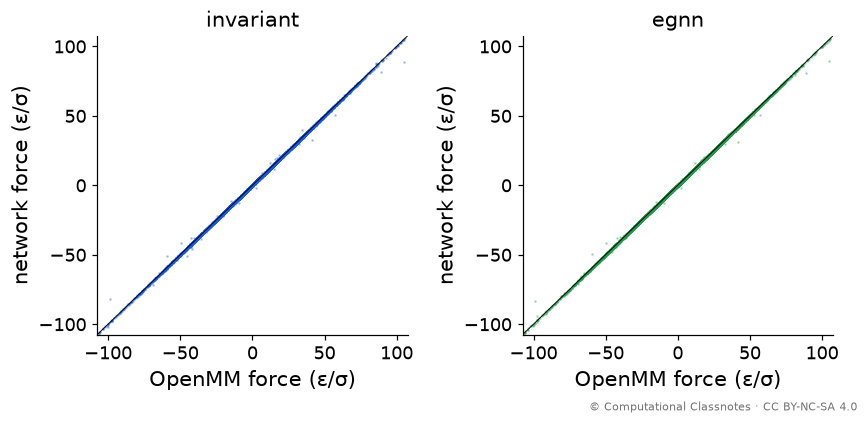

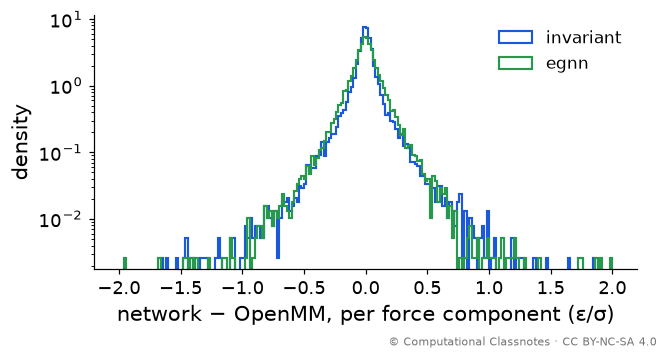

In [6]:
# c.5
# the full models on the 64-bead test chain
test, _ = dataset_from_npz(DATA / "kg_N64.npz", energy_offset=e0)
models = {n: load_model(ROOT / f"models/{n}.pt")[0] for n in ("invariant", "egnn")}
rows = [["model", "force RMSE (ε/σ)", "as % of RMS force", "energy RMSE per bead (ε)", "…of which a constant shift", "…the rest"]]
pred = {}
for n, m in models.items():
    r = evaluate(m, test); rows.append([n, f"{r['force_rmse']:.3f}", f"{100 * r['force_rmse'] / scale:.2f} %", f"{r['energy_rmse_per_bead']:.4f}",
                                        f"{r['energy_shift_per_bead']:+.4f}", f"{r['energy_rmse_per_bead_centred']:.5f}"])
    fp, fr = [], []
    for b in DataLoader(test[:100], batch_size=25):
        _, f = m(b); fp.append(f.detach().numpy().ravel()); fr.append(b.force.numpy().ravel())
    pred[n] = (np.concatenate(fr), np.concatenate(fp))
table(rows, "Table 6. Errors on the 64-bead test chain (300 frames, never seen)")
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.3, wHalf * 1.3))
for a, (n, (fr, fp)) in zip(ax, pred.items()):
    lim = np.percentile(np.abs(fr), 99.9); a.plot(fr, fp, ".", ms=1.5, alpha=.3, color=blue if n == "invariant" else green)
    a.plot([-lim, lim], [-lim, lim], "k", lw=.6); a.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="OpenMM force (ε/σ)", ylabel="network force (ε/σ)", title=n)
fig.tight_layout(); savefig(fig, "fig2_parity"); plt.show()
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.1))
for n, c in (("invariant", blue), ("egnn", green)):
    fr, fp = pred[n]; ax.hist(fp - fr, bins=200, range=(-2, 2), density=True, histtype="step", color=c, lw=1.4, label=n)
ax.set(xlabel="network − OpenMM, per force component (ε/σ)", ylabel="density", yscale="log"); ax.legend()
fig.tight_layout(); savefig(fig, "fig3_error_distribution"); plt.show()

*Figure 2. Every force component of 100 test frames of the 64-bead chain: network against OpenMM. Points on the diagonal are perfect predictions.*

*Figure 3. Distribution of the force errors on the test chain (log scale). Most errors are a few tenths of ε/σ, on forces of typical size 25 ε/σ. The rare larger errors come from strongly compressed bonds and close non-bonded contacts, where the forces are largest and the training frames fewest.*

## 6. The energy constant

Table 6 shows that on the 64-bead chain almost all of the energy error is one constant per bead; the rest is below 10⁻³ ε per bead. This is not a failure of training but a limit of what data at a single chain length can determine.

**Theorem 1 (what one chain length cannot fix).** Let the network energy be Ê = Σ_i ε(z_i, environment of i), with two bead types (ends and interior beads). Adding constants c_end and c_int to the per-bead energies of the two types changes neither the forces nor, for chains of N beads, the total energy, as long as

$$
2\, c_{\text{end}} + (N - 2)\, c_{\text{int}} = 0 . \tag{4}
$$

*Proof.* Constants have zero gradient, so the forces are unchanged. A chain of N beads has two ends and N − 2 interior beads, so its total energy changes by the left side of Eq. (4). ∎

Training on N = 32 alone therefore leaves one combination of the two constants free. On a chain of another length, the energy is shifted by

$$
\frac{\Delta \hat E}{N} = \frac{2 c_{\text{end}} + (N - 2) c_{\text{int}}}{N} , \qquad \text{with } 2c_{\text{end}} + 30\, c_{\text{int}} = 0 \text{ from training,} \tag{5}
$$

so a single measured shift at N = 64 determines both constants. Cell c.6 does this for both networks and predicts the shift at other lengths. Adding a second chain length to the training data would fix the constant. Forces and dynamics never depend on it.

In [7]:
# c.6
# Theorem 1: solve Eq. (5) for the two constants from the N = 32 and N = 64 shifts, and predict other lengths
rows = [["model", "shift at N = 32 (validation)", "shift at N = 64 (test)", "c_end", "c_int", "predicted shift at N = 16, 128"]]
for n, m in models.items():
    s32 = evaluate(m, val)["energy_shift_per_bead"]; s64 = evaluate(m, test)["energy_shift_per_bead"]
    Amat = np.array([[2, 30], [2, 62]]); rhs = np.array([s32 * 32, s64 * 64]); c_end, c_int = np.linalg.solve(Amat, rhs)
    pr = [(2 * c_end + (N - 2) * c_int) / N for N in (16, 128)]
    rows.append([n, f"{s32:+.4f}", f"{s64:+.4f}", f"{c_end:+.3f}", f"{c_int:+.4f}", f"{pr[0]:+.3f}, {pr[1]:+.3f} ε per bead"])
table(rows, "Table 7. The energy constant, Eqs. (4)–(5) (ε per bead)")

model,shift at N = 32 (validation),shift at N = 64 (test),c_end,c_int,"predicted shift at N = 16, 128"
invariant,+0.0188,-0.3354,+10.642,-0.6895,"+0.727, -0.512 ε per bead"
egnn,+0.0001,-0.0231,+0.696,-0.0463,"+0.047, -0.035 ε per bead"


## 7. Training your own models

*Table 8. Settings of `scripts/train.py` and what they do.*

| option | default | meaning |
|---|---|---|
| `--data` | (required) | training file from `scripts/generate_data.py` |
| `--test` | none | an extra file evaluated after training, e.g. a longer chain |
| `--model` | `invariant` | `invariant` (SchNet style) or `egnn` (EGNN style) |
| `--hidden`, `--layers` | 64, 3 | channels H and message-passing layers T |
| `--cutoff` | 1.5 | r_c of the non-bonded edges (σ) |
| `--epochs`, `--batch-size`, `--lr` | 30, 16, 0.002 | passes over the data, frames per step, Adam's η₀ |
| `--val-frac` | 0.1 | share of the frames kept for validation |
| `--device` | `cuda` if available | `cpu`, `cuda` or `mps` (Apple silicon) |
| `--threads` | 0 | CPU threads for PyTorch (0 = default) |
| `--out` | (required) | checkpoint path; the history goes next to it as `.json` |

To learn from coarse-grained data, map a data file with `polymer_nn.coarse_grain.coarse_grain_dataset` and train with the energy weight set to 0 (notebook 00, section 8). For large systems see `docs/running-large.md`.

## References

- [izvekov2005] S. Izvekov, G. A. Voth, J. Phys. Chem. B 109 (2005) 2469–2473. doi:10.1021/jp044629q
- [noid2008] W. G. Noid et al., J. Chem. Phys. 128 (2008) 244114. doi:10.1063/1.2938860
- [chmiela2017] S. Chmiela et al., Machine learning of accurate energy-conserving molecular force fields, Sci. Adv. 3 (2017) e1603015. doi:10.1126/sciadv.1603015
- [kingma2015] D. P. Kingma, J. Ba, Adam, ICLR 2015, arXiv:1412.6980.
- [loshchilov2017] I. Loshchilov, F. Hutter, SGDR: Stochastic gradient descent with warm restarts, ICLR 2017, arXiv:1608.03983.
- The complete bibliography: `docs/REFERENCES.md`.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>